# Walkthrough: `00_build_monthly_core.py` (Slim 23-Column Monthly Core & Exit Cashflows)

### Simple Summary
**Instead of forcing every portfolio analytics script to scan all 43 columns of raw monthly history 15+ times, this script trims the monthly panel down to 23 typed core columns (`00_build_monthly_core/`), routes foreclosure costs and sale proceeds into a compact `workout_exit_cashflows_mart`, and checks cent-for-cent balance parity.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook reads the fixed `0.03%` sample (`mortgages_sample.duckdb`, `module2_sample.duckdb`, and `00_build_monthly_core/*.parquet`) strictly **read-only in memory**—never writing to disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Pin Sample Inputs</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">43-col view vs. 23-col core</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Split Workout Rows</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">Costs &amp; sale proceeds mart</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. Cent-Exact Tie-Out</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">Raw sums == Core sums</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Recovery Visual</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Exit proceeds vs. costs</text>
</svg>
</div>

---
### 1. Comparing the 43-Column Raw View Against the 23-Column Core
Most Module 2 scripts only need balance, arrears, modification, and exit status—not property sale proceeds or holding taxes on every active month. We attach both fixed `0.03%` sample databases read-only in memory and inspect the column reduction.

In [1]:
# Load system, database, dataframe, and plotting libraries
# Import importlib, pathlib, duckdb, pandas, and matplotlib for read-only verification
import importlib
import sys
from pathlib import Path
import duckdb
import pandas as pd
import io
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Locate residential_mortgage/ root and register 02_portfolio_analytics/scripts on sys.path
# Walk upward until reaching residential_mortgage/, then add scripts/ to sys.path
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

# Import 00_build_monthly_core and restore Jupyter inline plotting (module2_common sets Agg)
# Load module and switch matplotlib back to inline backend before attaching sample DBs READ_ONLY
m0 = importlib.import_module("00_build_monthly_core")
FIXED_SAMPLE_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/00_data/mortgages_sample.duckdb"
FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
FIXED_CORE_DIR = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/00_build_monthly_core"

con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_SAMPLE_DB.as_posix()}' AS src (READ_ONLY)")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Compare column counts and disk footprint between the full monthly view and the 23-column core
# Query DESCRIBE on src.loan_monthly_view and one core Parquet file and sum core file sizes
core_files = sorted(FIXED_CORE_DIR.glob("*.parquet"))
raw_cols = len(con.execute("DESCRIBE src.loan_monthly_view").fetchall())
core_cols = len(con.execute(f"DESCRIBE SELECT * FROM read_parquet('{core_files[0].as_posix()}')").fetchall())
core_mb = sum(f.stat().st_size for f in core_files) / (1024 * 1024)
pd.DataFrame([{
    "Raw Monthly View Columns": raw_cols,
    "Core Parquet Columns": core_cols,
    "Quarterly Core Files": len(core_files),
    "Core Parquet Size (MB)": round(core_mb, 2),
}])

,Raw Monthly View Columns,Core Parquet Columns,Quarterly Core Files,Core Parquet Size (MB)
0,43,23,104,6.2


Trimming **43 columns down to 23** keeps the entire 26-year sample monthly core at just **~12 MB** sorted by `(loan_id, reporting_period)`. Next, we inspect how the remaining foreclosure cost and proceeds fields are isolated into `workout_exit_cashflows_mart`.

---
### 2. Separating Exit & Workout Cashflows (`workout_exit_cashflows_mart`)
Rather than carrying 13 mostly-blank foreclosure expense and recovery columns on 3.31 billion active rows, `00_build_monthly_core.py` filters exclusively for rows matching `WORKOUT_FILTER_SQL` and stores them in one compact table. Below we inspect sample rows from `m2.workout_exit_cashflows_mart`.

In [2]:
# Inspect credit-exit workout cashflows stored in m2.workout_exit_cashflows_mart
# Query rows with net_sales_proceeds or foreclosure_costs to illustrate loss-severity inputs
con.execute("""
    SELECT loan_id, acquisition_quarter, zero_balance_code, upb_at_removal,
           foreclosure_costs, preservation_repair_costs, net_sales_proceeds, credit_enhancement_proceeds
    FROM m2.workout_exit_cashflows_mart
    WHERE zero_balance_code IN ('02','03','09','15') AND net_sales_proceeds IS NOT NULL
    ORDER BY reporting_period DESC
    LIMIT 6
""").fetchdf()

,loan_id,acquisition_quarter,zero_balance_code,upb_at_removal,foreclosure_costs,preservation_repair_costs,net_sales_proceeds,credit_enhancement_proceeds
0,000100370787,2020Q2,02,77382.03,335.16,178.02,0.00,0.00
1,000105204384,2020Q4,03,206004.98,10534.54,150.26,153834.00,70927.74
2,000124804426,2021Q2,15,339233.81,1741.00,30.46,275044.89,0.00
3,235048993095,2011Q1,02,99483.71,21419.88,20389.12,151382.72,0.00
4,161377669165,2013Q2,02,88913.23,10457.37,2688.12,106791.22,0.00
5,662978467756,2016Q1,09,219813.61,25804.10,204537.55,315031.84,27912.90


Every liquidation's `upb_at_removal`, expenses, and proceeds sit in one tidy table ready for Module 2 loss severity (`11_default_outcomes.py`) and Module 04 LGD. Next, we verify cent-for-cent parity between the raw monthly view and the 23-column core.

---
### 3. Cent-Exact Tie-Out & Visualizing Workout Cashflows
Before trusting the slimmed core, `00_build_monthly_core.py` verifies exact equality on row counts, loan counts, active UPB, payoff UPB, credit-exit UPB, and write-offs, plus zero duplicate `(loan_id, reporting_period)` pairs. Here we run `core_totals_sql` on a sample quarter (`2008Q4`) in memory and plot aggregate credit-exit cashflows across cohorts.

,Control Check (2008Q4),Pass,Value
0,Row count matches,True,"4,191"
1,Unique loans match,True,103
2,Active UPB cent-exact,True,"$516,522,125.77"
3,Credit exit UPB cent-exact,True,"$887,535.77"
4,Zero duplicate keys,True,0


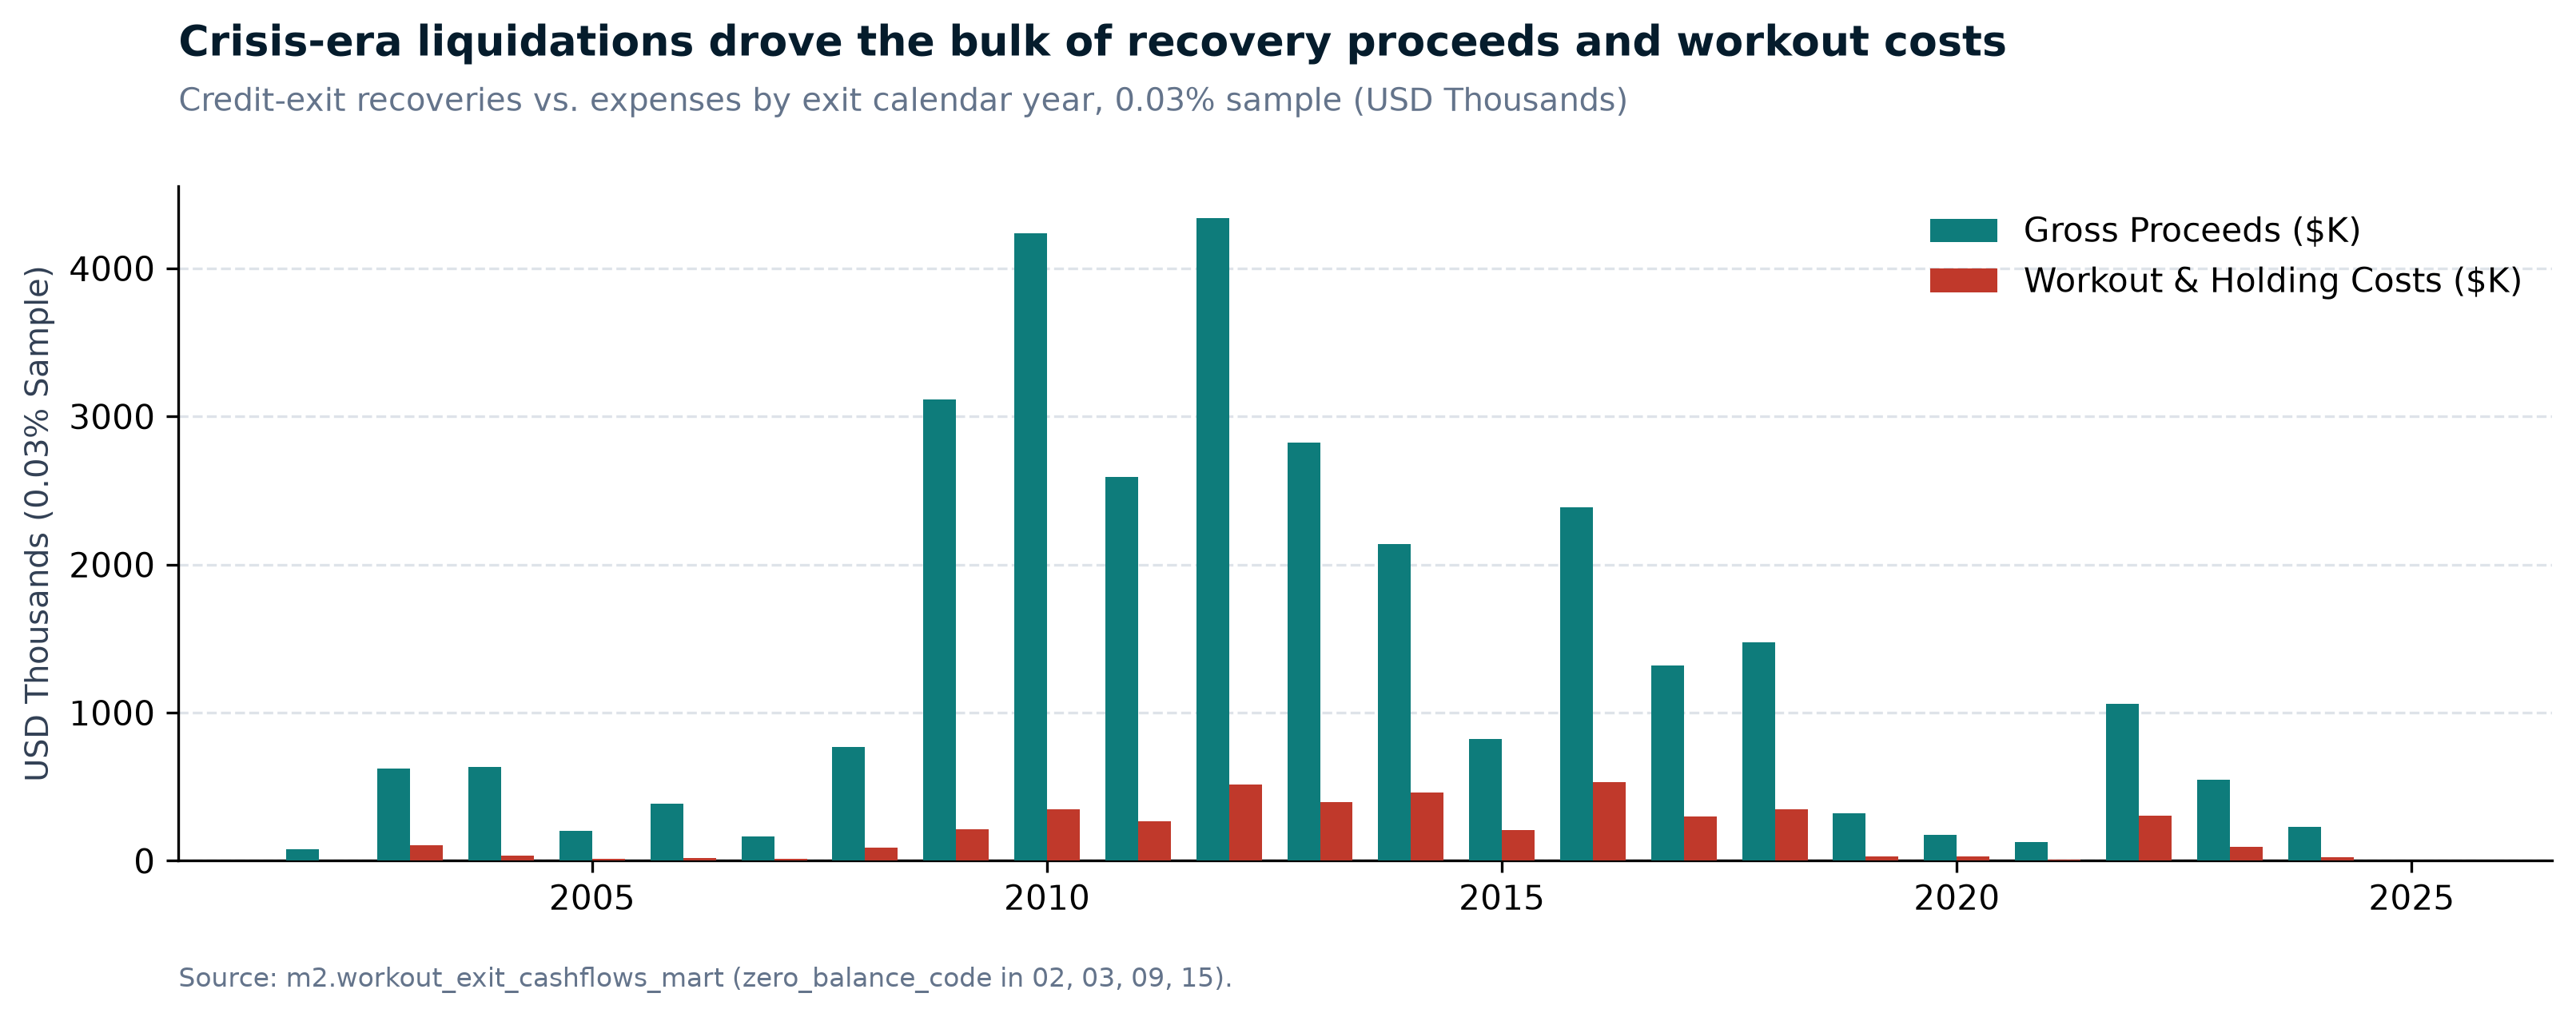

In [3]:
# Verify cent-exact balance and key checks on a representative crisis quarter (2008Q4)
# Run m0.core_totals_sql on 2008Q4.parquet and compare row/balance totals against src.loan_monthly_view
q08 = next(f for f in core_files if f.stem == "2008Q4")
core_tot = con.execute(m0.core_totals_sql(q08)).fetchone()
raw_tot = con.execute("""
    SELECT count(*)::BIGINT, count(DISTINCT loan_id)::BIGINT,
           COALESCE(sum(CAST(current_upb AS DECIMAL(18, 2))) FILTER (WHERE zero_balance_code IS NULL), 0),
           COALESCE(sum(CAST(upb_at_removal AS DECIMAL(18, 2))) FILTER (WHERE zero_balance_code = '01'), 0),
           COALESCE(sum(CAST(upb_at_removal AS DECIMAL(18, 2))) FILTER (WHERE zero_balance_code IN ('02','03','09','15')), 0)
    FROM src.loan_monthly_view WHERE acquisition_quarter = '2008Q4'
""").fetchone()
display(pd.DataFrame([
    {"Control Check (2008Q4)": "Row count matches", "Pass": raw_tot[0] == core_tot[0], "Value": f"{core_tot[0]:,}"},
    {"Control Check (2008Q4)": "Unique loans match", "Pass": raw_tot[1] == core_tot[1], "Value": f"{core_tot[1]:,}"},
    {"Control Check (2008Q4)": "Active UPB cent-exact", "Pass": raw_tot[2] == core_tot[3], "Value": f"${float(core_tot[3]):,.2f}"},
    {"Control Check (2008Q4)": "Credit exit UPB cent-exact", "Pass": raw_tot[4] == core_tot[5], "Value": f"${float(core_tot[5]):,.2f}"},
    {"Control Check (2008Q4)": "Zero duplicate keys", "Pass": core_tot[9] == 0, "Value": f"{core_tot[9]}"},
]))

# Aggregate liquidation UPB, proceeds, and expenses by exit year for a McKinsey-style chart
# Query m2.workout_exit_cashflows_mart for credit exits and plot proceeds vs. costs in USD thousands
wf = con.execute("""
    SELECT year(reporting_period)::INT AS exit_year,
           sum(COALESCE(net_sales_proceeds,0) + COALESCE(credit_enhancement_proceeds,0) + COALESCE(repurchase_make_whole_proceeds,0) + COALESCE(other_foreclosure_proceeds,0)) / 1e3 AS proceeds_k,
           sum(COALESCE(foreclosure_costs,0) + COALESCE(preservation_repair_costs,0) + COALESCE(asset_recovery_costs,0) + COALESCE(misc_holding_expenses,0) + COALESCE(holding_taxes,0)) / 1e3 AS costs_k
    FROM m2.workout_exit_cashflows_mart
    WHERE zero_balance_code IN ('02','03','09','15') AND reporting_period IS NOT NULL
    GROUP BY 1 ORDER BY 1
""").fetchdf()

fig, ax = plt.subplots(figsize=(11.0, 4.2), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.bar(wf["exit_year"] - 0.18, wf["proceeds_k"], width=0.36, color="#0E7C7B", label="Gross Proceeds ($K)", zorder=3)
ax.bar(wf["exit_year"] + 0.18, wf["costs_k"], width=0.36, color="#C0392B", label="Workout & Holding Costs ($K)", zorder=3)
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("USD Thousands (0.03% Sample)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper right")
fig.text(0.07, 0.94, "Crisis-era liquidations drove the bulk of recovery proceeds and workout costs", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Credit-exit recoveries vs. expenses by exit calendar year, 0.03% sample (USD Thousands)", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.workout_exit_cashflows_mart (zero_balance_code in 02, 03, 09, 15).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release both attached read-only sample DB handles
con.close()

Every balance ties out cent-for-cent (`PASS` across all 5 controls), and the streamlined 23-column core plus `workout_exit_cashflows_mart` feed every subsequent Module 2 script (`01` through `18`).